# Symbolic IK for a Planar 3R Robot Manipulator

An implementation of *Numerical algebraic geometry and algebraic kinematics* by Wampler et al. (Section 3.1.1)

The diagram of planar 3R is shown here

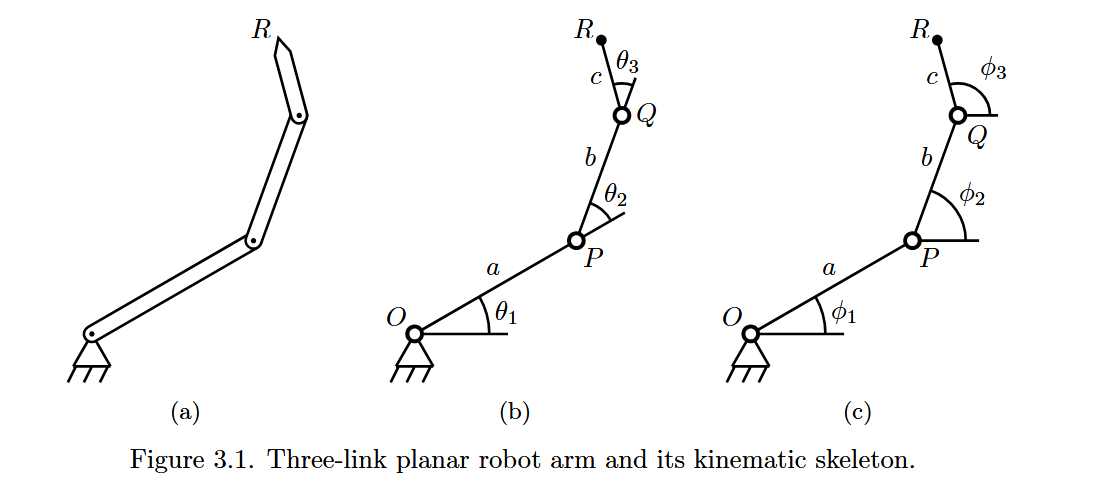


In [1]:
from sympy import *
init_printing(use_unicode=True)

Define variables

In [2]:
# phis are joint angles
# a,b,c are the link lengths
phi1, phi2, phi3 = symbols('phi1 phi2 phi3')
a, b, c = symbols('a b c')

Forward kinematics

In [3]:
# compute Rx, Ry
Rx = a*cos(phi1) + b*cos(phi2) + c*cos(phi3)
Ry = a*sin(phi1) + b*sin(phi2) + c*sin(phi3)

In [4]:
Rx

a⋅cos(φ₁) + b⋅cos(φ₂) + c⋅cos(φ₃)

In [5]:
Ry

a⋅sin(φ₁) + b⋅sin(φ₂) + c⋅sin(φ₃)

Inverse kinematics

Given $R_x, R_y, \phi_3$, compute $\phi_1, \phi_2$

In [48]:
phi3_val = 2*pi/5
a_val, b_val, c_val = 1, 1, 1
Rx_val = 1
Ry_val = 1

Qx = Rx_val - c_val*cos(phi3_val)
Qy = Ry_val - c_val*sin(phi3_val)

In [49]:
Qx

5   √5
─ - ──
4   4 

In [50]:
Qy

        ________
       ╱ √5   5 
1 -   ╱  ── + ─ 
    ╲╱   8    8 

A real solution exists exactly when the target distance $r = \sqrt{Q_x^2 + Q_y^2}$ satisfies:
$$
|a - b| \leq r \leq |a + b|
$$

In [58]:
r = sqrt(Qx**2 + Qy**2)
r.evalf()

assert abs(a_val - b_val) <= r and r <= abs(a_val + b_val)

Transfrom trigonometric to polynomial equation with variable substitution
$x_i = cos(\phi_i)$ and $y_i = sin(\phi_i)$ where $i = 1,2$
$x_i^2 + y_i^2 = 1$

In [59]:
x1, x2, y1, y2 = symbols('x1 x2 y1 y2')

In [60]:
x1

x₁

In [61]:
eqs = [
    a_val*x1 + b_val*x2 - Qx,
    a_val*y1 + b_val*y2 - Qy,
    x1**2 + y1**2 - 1,
    x2**2 + y2**2 - 1,
]

solutions = solve_poly_system(eqs, x1, y1, x2, y2)


In [62]:
pprint(solutions[0])

⎛                                        _____________________________________ ↪
⎜         ___________                   ╱            ________                  ↪
⎜  9415⋅╲╱ 2⋅√5 + 10              857⋅╲╱  - 40⋅√10⋅╲╱ √5 + 5  - 150 + 70⋅√5 +  ↪
⎜- ────────────────── - 6350⋅√5 - ──────────────────────────────────────────── ↪
⎜          2                                                    4              ↪
⎜───────────────────────────────────────────────────────────────────────────── ↪
⎜                                                                              ↪
⎝                                                                              ↪

↪ __________________           _______________________________________________ ↪
↪          ________           ╱           ________                        ____ ↪
↪ 100⋅√2⋅╲╱ √5 + 5     1235⋅╲╱  - 6⋅√10⋅╲╱ √5 + 5  - 22 + 10⋅√5 + 14⋅√2⋅╲╱ √5  ↪
↪ ────────────────── - ─────────────────────────────────────────────────────── ↪
↪                          

In [63]:
solutions[0][0].evalf(),solutions[0][1].evalf() 

(0.411772828548634, -0.911286528853059)

In [64]:
solutions[1][0].evalf(),solutions[1][1].evalf()

(0.279210177076418, 0.960230012557905)